# Linear Algebra for Data Science 2026 — Lab 2, Core B
# Markov chains and PageRank

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after O. Dyhdalovych & R. Hryniv, 2023 </div>

## Completed by:
*   Markiian Yatsyshyn
*   Bohdan Prokhorov

**Marked at the defence:** Core B is worth 2 points; the starred extension B1 at the end is one of three routes to the extension point (see the brief).

## Why this core

How popular is a web page, a paper or a user in a social network? PageRank answers with the stationary distribution of a random walk, which is an eigenvector of a huge, sparse, non-negative matrix. This core takes you from the naive model to the version that actually runs: you will see the model fail in three different ways, repair it with one rank-one term, **predict how fast the repaired iteration converges**, and run it on a graph with $10^5$ nodes without ever forming the matrix.

**Uses:** Lecture 3.2 (stochastic matrices, Perron–Frobenius, PageRank, power iteration). Core A's `power_method` is the same algorithm; here it gets a matrix-free form.

**Rules for this notebook**
* `np.linalg.eig`/`eigvals` are allowed **only to check** results on small graphs (§1, §3, §4). Your PageRank code must not call them.
* `networkx` is used for drawing small graphs, for generating the large test graph and, once, as an independent check in §5. Do not use it to compute ranks anywhere else.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, time, numpy as np, scipy, scipy.sparse as sp, networkx as nx, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.13.16 | numpy 2.1.3 | scipy 1.16.3 | networkx 3.7 | matplotlib 3.10.0


## The convention used throughout

Pages are numbered $0,\dots,n-1$. The **adjacency matrix** $G$ has
$$
G_{jk} = 1 \iff \text{page } k \text{ links to page } j,
$$
so **column $k$ lists the out-links of page $k$**, and the number of out-links $N_k$ is the $k$-th column sum. The link matrix of Lecture 3.2 is
$$
p_{jk} = \begin{cases} 1/N_k, & k \to j,\\ 0, & \text{otherwise,}\end{cases}
$$
so $p_{jk}$ is the probability of moving **from $k$ to $j$**, and every column of $P$ with $N_k > 0$ sums to $1$. Ranks are column vectors $\mathbf{r}$, updated by $\mathbf{r}_{n+1} = P\mathbf{r}_n$.

*(Last year's notebook stated this convention backwards in one place. If you find older material online, check its convention before reusing anything.)*

In [2]:
def plot_graph(G, ranks, title=''):
    # draws the graph with arrows k -> j for G[j, k] = 1, and the ranks under the labels
    graph = nx.from_numpy_array(np.asarray(G).T, create_using=nx.DiGraph)
    pos = nx.circular_layout(graph)
    plt.figure(figsize=(5, 4))
    nx.draw(graph, pos=pos, node_size=1600, node_color='w', edgecolors='k', linewidths=2,
            connectionstyle='arc3,rad=0.1', arrowsize=18)
    nx.draw_networkx_labels(graph, pos=pos, labels={v: f'{v}\n{ranks[v]:.3f}' for v in graph.nodes()})
    plt.title(title); plt.show()

---
## 1. The random surfer

### 1.1 Implement the two building blocks
* `link_matrix(G)` returns $P$ as above. Columns of pages with no out-links ("dead ends") stay zero for now.
* `power_markov(M, r0, tol, max_iter)` iterates $\mathbf{r}_{n+1} = M\mathbf{r}_n$. Here `M` may be a matrix **or a function** `x -> M x`; that is what will let you reuse it unchanged in §5. Stop when $\|\mathbf{r}_{n+1} - \mathbf{r}_n\|_1 \le$ `tol`. Return the final vector and a history with the 1-norm increments and the sums $\mathbf{1}^\top\mathbf{r}_n$.

**Question 1.1.** Core A normalised the iterate at every step. Why is no normalisation needed here, as long as $M$ is column-stochastic?

---
**Your answer here**

**Answer 1.1.** For a column-stochastic $M$ we have $\mathbf 1^\top M = \mathbf 1^\top$, hence $\mathbf 1^\top M\mathbf r = \mathbf 1^\top\mathbf r$: **the sum of the entries is preserved at every step**. Also $M\ge 0$ keeps the entries non-negative. So if $\mathbf r_0$ is a probability distribution, every $\mathbf r_n$ is one too, and its length cannot blow up or die out.

In Core A the dominant eigenvalue $\lambda_1$ is arbitrary, so $\|A^n\mathbf x_0\|\sim|\lambda_1|^n$ grows or shrinks and we must rescale. Here $\mathbf 1^\top$ is a left eigenvector for the eigenvalue $1$, and $\|M\mathbf x\|_1\le\|\mathbf x\|_1$ (see 3.2(b)) shows that no eigenvalue exceeds $1$ in modulus. So $\lambda_1 = 1$ exactly and the scaling is built in. (It also means that $\mathbf 1^\top\mathbf r_n$ is a free diagnostic: §2 uses it to detect the leak.)

---

In [3]:
def link_matrix(G):
    '''Column-stochastic link matrix P of Lecture 3.2; zero columns for dead ends.'''
    # YOUR CODE HERE
    G = np.asarray(G, dtype=float)
    N = G.sum(axis=0)                                   # N[k] = number of out-links of page k
    return np.divide(G, N[None, :], out=np.zeros_like(G), where=(N > 0)[None, :])#якщо сума елементів N(кількості переходів) у певній вершині графа > 0, то ми ділимо на цю суму, щоб пронормувати
    #але якщо - це глухий кут і у нас кількість переходів =0, то ми не ділимо на 0, щоб не було помилки, а просто переписуємо 0

#степеневим методом знаходимо Стаціонарний розподіл ланцюгів  маркова
def power_markov(M, r0=None, tol=1e-10, max_iter=1000):
    '''
    Iterate r <- M r until ||r_new - r||_1 <= tol.
    M is an (n, n) array, a sparse matrix, or a function x -> M x.
    r0 defaults to the uniform distribution; then n must be inferable from M.
    Returns r and a dict with arrays 'inc' (1-norm increments) and 'sum' (sums of r_n).
    '''
    # YOUR CODE HERE
    # note: hist['sum'] has one more entry than hist['inc'] (it starts with the sum of r_0)
    matvec = M if callable(M) else (lambda x: M @ x)
    if r0 is None:
        n = M.shape[0]                                  # arrays, sparse matrices, or functions with a .shape
        r0 = np.full(n, 1.0 / n)
    r = np.array(r0, dtype=float)                       # якщо вектор заданих, то просто копіюємо його, не змінюючи, якщо не заданий то робимо його рівномірнорозподіленим 1/n, 1/n ..
    inc, sums = [], [r.sum()]
    for _ in range(max_iter):
        r_new = matvec(r)#робимо один крок випадкового серфера (множимо матрицю на поточний вектор рангів).
        inc.append(np.abs(r_new - r).sum())             # 1-norm increment
        sums.append(r_new.sum())
        r = r_new
        if inc[-1] <= tol:
            break
    return r, {'inc': np.array(inc), 'sum': np.array(sums)}

### 1.2 First test
Run the iteration on the graph below from the uniform distribution and from two other starting distributions of your choice. Check the result against the eigenvector of $P$ for $\lambda = 1$ obtained from `np.linalg.eig` (normalise it to sum 1). Which page ranks highest? Explain *from the graph* why that is reasonable.

out-degrees N_k       : [2 3 2 1]
column sums of P      : [1. 1. 1. 1.]
start uniform : iterations  62, r = [0.206897 0.413793 0.137931 0.241379], sum = 1.000000000000
start e_0     : iterations  63, r = [0.206897 0.413793 0.137931 0.241379], sum = 1.000000000000
start random  : iterations  56, r = [0.206897 0.413793 0.137931 0.241379], sum = 1.000000000000

eigenvector for lambda = 1, normalised to sum 1: [0.206897 0.413793 0.137931 0.241379]
moduli of all eigenvalues of P: [1.     0.6924 0.3469 0.3469]
  max |r - r_eig| for start uniform : 1.73e-11
  max |r - r_eig| for start e_0     : 1.43e-11
  max |r - r_eig| for start random  : 2.00e-11
page with the highest rank: 1


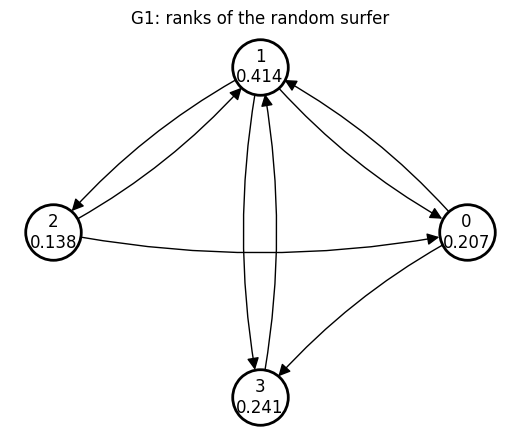

In [4]:
G1 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 1],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

# YOUR CODE HERE
P1 = link_matrix(G1)
print('out-degrees N_k       :', G1.sum(axis=0))#сума по стовпцях не нормованих
print('column sums of P      :', P1.sum(axis=0))#перевірка, чи матриця стохастична, якщо всі 1 - матриця стохастична

#вибір різних старотових станів( векторів r0 ймовірності)
starts = {'uniform': np.full(4, 0.25),
          'e_0': np.array([1., 0., 0., 0.]),
          'random': rng.dirichlet(np.ones(4))} #випадковий початковий розподіл, згідно розподілу Діріхле(моделює випадкові вектори ймовірностей)
res = {}
for name, r0 in starts.items():
    r, h = power_markov(P1, r0)
    res[name] = r
    print(f'start {name:8s}: iterations {len(h["inc"]):3d}, r = {np.round(r, 6)}, sum = {r.sum():.12f}')

lam, V = np.linalg.eig(P1)    #суто для перевірки результатів
i = np.argmin(np.abs(lam - 1))
r_eig = np.real(V[:, i]); r_eig /= r_eig.sum()
print('\neigenvector for lambda = 1, normalised to sum 1:', np.round(r_eig, 6))
print('moduli of all eigenvalues of P:', np.round(np.sort(np.abs(lam))[::-1], 4))
for name, r in res.items():
    print(f'  max |r - r_eig| for start {name:8s}: {np.abs(r - r_eig).max():.2e}')
print('page with the highest rank:', int(np.argmax(res['uniform'])))
plot_graph(G1, res['uniform'], 'G1: ranks of the random surfer')

---
**Your answer here**

**Answer 1.2.** From all three starts the iteration reaches $\mathbf r\approx(0.2069,\ 0.4138,\ 0.1379,\ 0.2414)=\tfrac1{29}(6,12,4,7)$ and agrees with the $\lambda=1$ eigenvector from `np.linalg.eig` to about $2\cdot10^{-11}$.

**Page 1 ranks highest.** It is linked from three pages (0, 2 and 3), and page 3's only out-link goes to page 1, so page 3 hands over *all* its rank. The stationary equation is $r_1=\tfrac12 r_0+\tfrac12 r_2+r_3$, i.e. $12=\tfrac12\cdot 6+\tfrac12\cdot 4+7$ (in units of $1/29$). Page 3 is second because it is linked from both 0 and 1, the two pages that carry most rank.

---

Чому саме 62-63 ітерації?

Це пов'язано з другим за модулем власним значенням \(\lambda_2 \approx 0.6924\). Оскільки похибка на кожному кроці зменшується в \(0.6924\) раза, для досягнення точності \(10^{-10}\) теоретично потрібно \(\frac{\ln(10^{-10})}{\ln(0.6924)} \approx 62\) кроки, що повністю підтверджено практичним експериментом

---
## 2. Dead ends

### 2.1 What goes wrong
In the graph `G2` below, page 3 has no out-links. Run the iteration and plot the sums $\mathbf{1}^\top\mathbf{r}_n$ against $n$. Explain what you see using the column sums of $P$: show that $\mathbf{1}^\top\mathbf{r}_{n+1} = \mathbf{1}^\top\mathbf{r}_n - \mathbf{d}^\top\mathbf{r}_n$, where $\mathbf{d}$ marks the dead ends ($d_k = 1$ if $N_k = 0$, else $0$).

### 2.2 The repair
Let the surfer jump from a dead end to a uniformly random page:
$$
P_d := P + \tfrac1n\,\mathbf{1}\mathbf{d}^\top .
$$
Implement `fix_dead_ends(P)` and rerun. Check that $P_d$ is column-stochastic.

[[0.         0.33333333 0.5        0.        ]
 [0.5        0.         0.5        0.        ]
 [0.         0.33333333 0.         0.        ]
 [0.5        0.33333333 0.         0.        ]]
column sums of P: [1. 1. 1. 0.]   d = [0. 0. 0. 1.]
max violation of the identity 1^T r_(n+1) = 1^T r_n - d^T r_n over 20 steps: 1.1e-16
naive iteration: 58 iterations, final r = [3.84172812e-11 4.47624638e-11 2.20800663e-11 5.05053152e-11], sum = 1.558e-10
ratio of successive sums at the end of the run: 0.6758


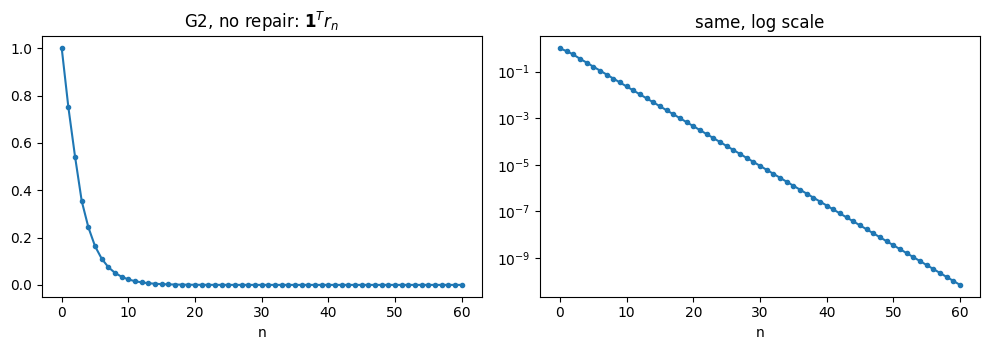


column sums of P_d      : [1. 1. 1. 1.] | all entries >= 0: True
repaired iteration: 20 iterations, r = [0.252632 0.284211 0.168421 0.294737], sum = 1.000000000000
sums 1^T r_n stay at exactly 1: True
check: ||P_d r - r||_1 = 1.4e-11;  95 * r = [24. 27. 16. 28.]


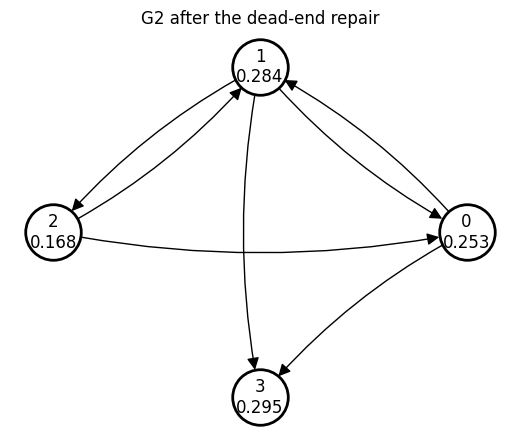

In [15]:
G2 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 0],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

def fix_dead_ends(P):
    '''P_d = P + (1/n) 1 d^T (dense; for small graphs only).'''
    # YOUR CODE HERE
    n = P.shape[0]
    d = (P.sum(axis=0) == 0).astype(float)              # d_k = 1 iff page k is a dead end (zero column)
    return P + np.outer(np.ones(n), d) / n

# YOUR CODE HERE
# --- 2.1: what goes wrong
P2 = link_matrix(G2)
d2 = (P2.sum(axis=0) == 0).astype(float)
print(P2)
print('column sums of P:', P2.sum(axis=0), '  d =', d2)

r = np.full(4, 0.25)
err = 0.0
for _ in range(20):                                     # check 1^T r_{n+1} = 1^T r_n - d^T r_n
    r_new = P2 @ r
    err = max(err, abs(r_new.sum() - (r.sum() - d2 @ r)))
    r = r_new
print(f'max violation of the identity 1^T r_(n+1) = 1^T r_n - d^T r_n over 20 steps: {err:.1e}')

r, h = power_markov(P2, tol=1e-10, max_iter=100)
print(f'naive iteration: {len(h["inc"])} iterations, final r = {r}, sum = {r.sum():.3e}')
r_plot, h_plot = power_markov(P2, tol=0, max_iter=60)
print(f'ratio of successive sums at the end of the run: {h_plot["sum"][-1] / h_plot["sum"][-2]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(h_plot['sum'], 'o-', ms=3); ax[0].set_title('G2, no repair: $\\mathbf{1}^T r_n$'); ax[0].set_xlabel('n')
ax[1].semilogy(h_plot['sum'], 'o-', ms=3); ax[1].set_title('same, log scale'); ax[1].set_xlabel('n')
plt.tight_layout(); plt.show()

# --- 2.2: the repair
Pd2 = fix_dead_ends(P2)
print('\ncolumn sums of P_d      :', Pd2.sum(axis=0), '| all entries >= 0:', bool((Pd2 >= 0).all()))
r2, h2 = power_markov(Pd2)
print(f'repaired iteration: {len(h2["inc"])} iterations, r = {np.round(r2, 6)}, sum = {r2.sum():.12f}')
print('sums 1^T r_n stay at exactly 1:', bool(np.allclose(h2['sum'], 1.0)))
print(f'check: ||P_d r - r||_1 = {np.abs(Pd2 @ r2 - r2).sum():.1e};  95 * r = {np.round(95 * r2, 4)}')
plot_graph(G2, r2, 'G2 after the dead-end repair')

---
**Your answer here**

**Answer 2.1.** For page $k$ with $N_k>0$ column $k$ of $P$ sums to $1$; for a dead end it sums to $0$. In vector form $\mathbf 1^\top P=\mathbf 1^\top-\mathbf d^\top$, so
$$\mathbf 1^\top\mathbf r_{n+1}=\mathbf 1^\top P\mathbf r_n=(\mathbf 1^\top-\mathbf d^\top)\mathbf r_n=\mathbf 1^\top\mathbf r_n-\mathbf d^\top\mathbf r_n .$$
(Checked numerically: the identity holds to $10^{-16}$.) Every step loses the rank sitting on page 3, i.e. probability **leaks out of the system**. The plot shows the sum decaying geometrically, each step by a factor $\approx0.676$ (the spectral radius of $P$, read off the last two sums). The iteration "converges" to $\mathbf r=\mathbf 0$ after 58 steps: it stops because the *increment* is tiny, but the limit is the useless zero vector.

**Answer 2.2.** In $P_d=P+\frac1n\mathbf 1\mathbf d^\top$ a dead-end column becomes the uniform column $\frac1n\mathbf 1$. All columns now sum to $1$ and all entries are $\ge0$ (checked), so $P_d$ is column-stochastic, the sum stays exactly $1$, and the iteration converges to $\mathbf r=\tfrac1{95}(24,27,16,28)$, which is a fixed point of $P_d$ ($\|P_d\mathbf r-\mathbf r\|_1\approx10^{-11}$). The former dead end, page 3, now has the highest rank: it is linked from pages 0 and 1, and a surfer stuck there teleports uniformly instead of disappearing.

---

---
## 3. When the answer is not unique, or the iteration does not settle

### 3.1 Three graphs, three problems
Run `power_markov` (on $P_d$) for the three graphs below, each from **at least three** starting distributions: the uniform one, $\mathbf{e}_0$, and one more. Use `max_iter=200`. For each graph, describe what happens. Then compute the eigenvalues of $P_d$ (here you may use `np.linalg.eigvals`), plot them in the complex plane together with the unit circle, and explain each behaviour **from the spectrum**.

* `G6`: does every page get a sensible rank? Does the iteration converge from every start?
* `G4` (a directed cycle): why does the uniform start *seem* to converge immediately?
* `G2c` (two separate parts): does the limit depend on the start?

=== G6 (n = 6), undamped P_d ===
  start uniform : 135 iterations, last increment 8.6e-11 (converged)
       r        = [0.5 0.5 0.  0.  0.  0. ]
  start e_0     : 200 iterations, last increment 2.0e+00 (NOT converged)
       r        = [1. 0. 0. 0. 0. 0.]
       P_d r    = [0. 1. 0. 0. 0. 0.]   <- one more step
  start random  : 200 iterations, last increment 5.2e-02 (NOT converged)
       r        = [0.5129 0.4871 0.     0.     0.     0.    ]
       P_d r    = [0.4871 0.5129 0.     0.     0.     0.    ]   <- one more step
=== G4 (n = 4), undamped P_d ===
  start uniform :   1 iterations, last increment 0.0e+00 (converged)
       r        = [0.25 0.25 0.25 0.25]
  start e_0     : 200 iterations, last increment 2.0e+00 (NOT converged)
       r        = [1. 0. 0. 0.]
       P_d r    = [0. 0. 0. 1.]   <- one more step
  start random  : 200 iterations, last increment 7.4e-01 (NOT converged)
       r        = [0.2685 0.4421 0.2182 0.0712]
       P_d r    = [0.4421 0.2182 0.0712 0.2685]   <

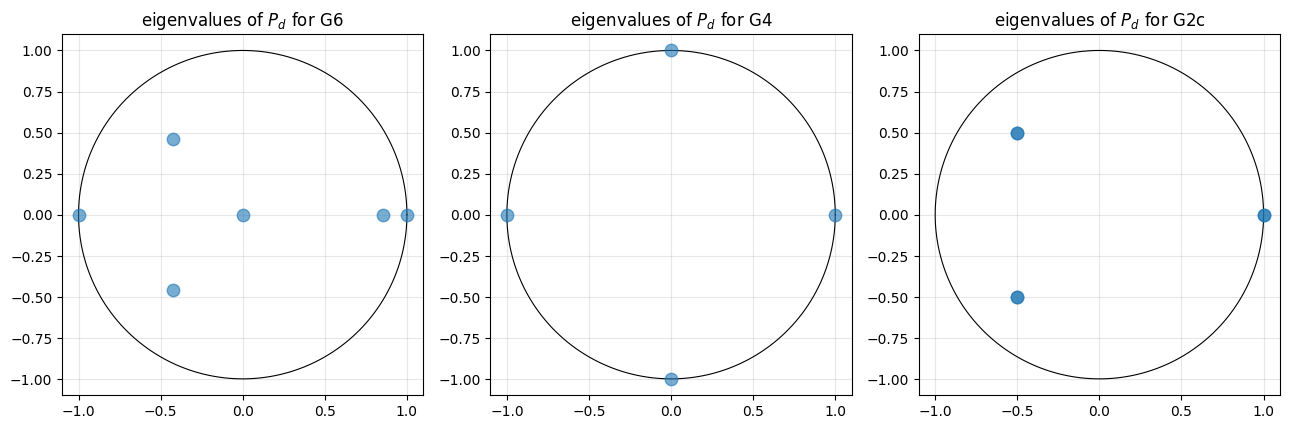

In [6]:
G6 = np.array([[0, 1, 0, 0, 0, 1],
               [1, 0, 1, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [0, 0, 1, 0, 0, 1],
               [0, 0, 0, 1, 0, 0]])
G4 = np.array([[0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1],
               [1, 0, 0, 0]])
G2c = np.zeros((6, 6), dtype=int)
for k, j in [(0, 1), (1, 2), (2, 0), (0, 2), (3, 4), (4, 5), (5, 3), (3, 5)]:   # link k -> j
    G2c[j, k] = 1

# YOUR CODE HERE
graphs = {'G6': G6, 'G4': G4, 'G2c': G2c}
Pd_of = {name: fix_dead_ends(link_matrix(G)) for name, G in graphs.items()}
starts_of = {}
for name, Pd in Pd_of.items():
    n_ = Pd.shape[0]
    e0 = np.zeros(n_); e0[0] = 1.0
    starts_of[name] = {'uniform': np.full(n_, 1.0 / n_), 'e_0': e0, 'random': rng.dirichlet(np.ones(n_))}
    print(f'=== {name} (n = {n_}), undamped P_d ===')
    for sname, r0 in starts_of[name].items():
        r, h = power_markov(Pd, r0, tol=1e-10, max_iter=200)
        ok = h['inc'][-1] <= 1e-10
        print(f'  start {sname:8s}: {len(h["inc"]):3d} iterations, last increment {h["inc"][-1]:.1e} '
              f'({"converged" if ok else "NOT converged"})')
        print('       r        =', np.round(r, 4))
        if not ok:
            print('       P_d r    =', np.round(Pd @ r, 4), '  <- one more step')

# --- spectra
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
th = np.linspace(0, 2 * np.pi, 400)
print()
for ax, (name, Pd) in zip(axes, Pd_of.items()):
    lam = np.linalg.eigvals(Pd)                                   # allowed: we only look at the spectrum
    ax.plot(np.cos(th), np.sin(th), 'k-', lw=0.8)
    ax.plot(lam.real, lam.imag, 'o', ms=9, alpha=0.6)
    ax.set_aspect('equal'); ax.set_title(f'eigenvalues of $P_d$ for {name}'); ax.grid(alpha=0.3)
    on_circle = lam[np.abs(lam) > 1 - 1e-9]
    print(f'{name}: eigenvalues on the unit circle: {np.round(on_circle, 4)}')
    print(f'      the rest, by modulus: {np.round(sorted(lam[np.abs(lam) <= 1 - 1e-9], key=lambda z: -abs(z)), 4)}')
plt.tight_layout(); plt.show()

---
**Your answer here**

**Answer 3.1.** Power iteration $\mathbf r_n=P_d^n\mathbf r_0$ settles down to a unique vector from every start exactly when $\lambda=1$ is a *simple* eigenvalue and **all other** eigenvalues have modulus $<1$. Each graph violates this in a different way.

**`G6`.** Pages 0 and 1 link only to each other, so the walk can enter $\{0,1\}$ (via $2\to1$ and $5\to0$) but never leave. All rank drains into this group and pages 2–5 get rank $0$: no sensible ranking. In addition, the 2-cycle $0\leftrightarrow1$ gives the eigenvalue $-1$. The spectrum has two eigenvalues on the unit circle, $1$ and $-1$ (the rest: $0.851$, a complex pair of modulus $0.626$, and $0$). The uniform start converges (to $(\tfrac12,\tfrac12,0,0,0,0)$, in 135 steps, slowly because of the eigenvalue $0.851$): its component along the $-1$ eigenvector happens to vanish. From $\mathbf e_0$ and from the random start the iteration does **not** converge: the mass sits on pages 0 and 1 and the two values swap at each step ($(1,0,\dots)\to(0,1,\dots)\to\dots$; last increment $2.0$ and $0.05$).

**`G4`.** A directed cycle: $P_d$ is a cyclic shift, with eigenvalues the 4th roots of unity $1,i,-1,-i$ — all four on the unit circle. The uniform vector is the eigenvector for $\lambda=1$, so $\mathbf r_1=\mathbf r_0$: the increment is $0$ after one step and the iteration *seems* to converge immediately. From any other start the vector just rotates around the cycle (from $\mathbf e_0$ the last increment is $2.0$) and never settles. The stationary distribution is unique ($\lambda=1$ is simple), but $\lambda=1$ is not *dominant*: $i,-1,-i$ have the same modulus.

**`G2c`.** Two parts with no links between them: $P_d$ is block diagonal, each block has its own eigenvalue $1$, so $\lambda=1$ is **double** (the other eigenvalues are $-0.5\pm0.5i$, each twice, modulus $0.707$). Then the stationary vector is not unique: any $t\boldsymbol\pi_A\oplus(1-t)\boldsymbol\pi_B$ works, and the iteration conserves the mass of each block, so the limit depends on the start: uniform start gives $(0.2,0.1,0.2,\,0.2,0.1,0.2)$ (half the mass in each block), $\mathbf e_0$ gives $(0.4,0.2,0.4,0,0,0)$, and the random start gives $(0.119,0.060,0.119,\,0.281,0.141,0.281)$, reflecting its initial mass $0.30$ vs $0.70$ in the two blocks. It converges (in about 65–70 steps $\approx \ln10^{-10}/\ln0.707$), but to a start-dependent answer.

---

### 3.2 The repair: damping
With $0 < \alpha < 1$ (Google's choice was $\alpha \approx 0.85$), the surfer follows a link with probability $\alpha$ and jumps to a uniformly random page with probability $1-\alpha$:
$$
\widetilde P := \alpha P_d + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top .
$$
*Careful: here, as in the lecture, $\alpha$ is the probability of **following a link**. Last year's notebook used $\alpha$ for the jump probability, i.e. our $1-\alpha$.*

**(a)** Show that $\widetilde P$ is column-stochastic and entrywise positive. What does Perron–Frobenius (Lecture 3.2) then guarantee?

**(b)** Prove the bound from the lecture: every eigenvalue $\lambda \ne 1$ of $\widetilde P$ satisfies $|\lambda| \le \alpha$. *Hint:* let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$. Use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$ to show that $\mathbf{1}^\top\mathbf{w} = 0$, and conclude that $\lambda/\alpha$ is an eigenvalue of $P_d$. Why can no eigenvalue of a column-stochastic matrix exceed 1 in modulus? *(Consider the norm $\|\cdot\|_1$.)*

---
**Your answer here**

**Answer 3.2(a).** *Column-stochastic:* $\mathbf 1^\top\widetilde P=\alpha\,\mathbf 1^\top P_d+\frac{1-\alpha}{n}\,(\mathbf 1^\top\mathbf 1)\,\mathbf 1^\top=\alpha\mathbf 1^\top+(1-\alpha)\mathbf 1^\top=\mathbf 1^\top$. *Positive:* $P_d\ge0$, so every entry of $\widetilde P$ is $\ge\frac{1-\alpha}{n}>0$ (the smallest entries found in §3.3 are $0.025$ and $0.0375$, which equal $0.15/n$ for $n=6$ and $n=4$).

For a positive column-stochastic matrix Perron–Frobenius guarantees: $\lambda=1$ is a **simple** eigenvalue; all other eigenvalues satisfy $|\lambda|<1$; and the eigenvector for $\lambda=1$ can be chosen strictly positive, with sum $1$. So the PageRank vector exists and is unique, and the power iteration converges to it from *every* starting distribution — this fixes all three failures of §3.1.

**Answer 3.2(b).** *Step 1: a bound for $P_d$.* For a column-stochastic $M$ and any $\mathbf x$,
$$\|M\mathbf x\|_1=\sum_j\Bigl|\sum_k M_{jk}x_k\Bigr|\le\sum_k|x_k|\sum_j M_{jk}=\|\mathbf x\|_1 .$$
If $M\mathbf v=\mu\mathbf v$ with $\mathbf v\neq0$, then $|\mu|\,\|\mathbf v\|_1=\|M\mathbf v\|_1\le\|\mathbf v\|_1$, so $|\mu|\le1$. This holds for $P_d$ and $\widetilde P$.

*Step 2.* Let $\widetilde P\mathbf w=\lambda\mathbf w$, $\mathbf w\ne0$, $\lambda\ne1$. Multiply by $\mathbf 1^\top$ from the left: $\mathbf 1^\top\mathbf w=\mathbf 1^\top\widetilde P\mathbf w=\lambda\,\mathbf 1^\top\mathbf w$, so $(1-\lambda)\mathbf 1^\top\mathbf w=0$ and, as $\lambda\ne1$, $\mathbf 1^\top\mathbf w=0$. Then the rank-one term vanishes, $\mathbf 1\mathbf 1^\top\mathbf w=0$, and
$$\lambda\mathbf w=\widetilde P\mathbf w=\alpha P_d\mathbf w\quad\Longrightarrow\quad P_d\mathbf w=\tfrac{\lambda}{\alpha}\mathbf w .$$
So $\lambda/\alpha$ is an eigenvalue of $P_d$, and by Step 1 $|\lambda/\alpha|\le1$, i.e. $|\lambda|\le\alpha$. $\blacksquare$

*Remark (used in §4).* The converse also holds: if $P_d\mathbf v=\mu\mathbf v$ with $\mu\neq1$, then $\mathbf 1^\top\mathbf v=0$ (same argument) and so $\widetilde P\mathbf v=\alpha\mu\mathbf v$. Hence the spectrum of $\widetilde P$ is $\{1\}$ together with $\alpha\times$(the other eigenvalues of $P_d$), and $|\lambda_2(\widetilde P)|=\alpha\,|\mu_2(P_d)|$.

---

### 3.3 Implement and test
Write `google_matrix(G, alpha)` (dense — small graphs only) and rerun the three graphs of §3.1 from the same starts. Does the iteration converge now, and to a unique answer? Then, for `G6`, tabulate the ranks for $\alpha \in \{0.5, 0.85, 0.99\}$. What happens to pages 2–5 as $\alpha \to 1$, and why?

In [7]:
def google_matrix(G, alpha=0.85):
    '''P_tilde = alpha * P_d + (1 - alpha)/n * 1 1^T  (dense; alpha = probability of FOLLOWING a link).'''
    # YOUR CODE HERE
    Pd = fix_dead_ends(link_matrix(G))
    n = Pd.shape[0]
    return alpha * Pd + (1 - alpha) / n * np.ones((n, n))

# YOUR CODE HERE
# (a) column-stochastic and positive?
for name, G in graphs.items():
    Pt = google_matrix(G, 0.85)
    print(f'{name}: column sums = {np.round(Pt.sum(axis=0), 12)}, smallest entry = {Pt.min():.4f}')

# rerun the three graphs from the same starts
print()
for name, G in graphs.items():
    Pt = google_matrix(G, 0.85)
    finals = []
    for sname, r0 in starts_of[name].items():
        r, h = power_markov(Pt, r0, tol=1e-10, max_iter=200)
        finals.append(r)
        print(f'{name:3s} start {sname:8s}: {len(h["inc"]):3d} iterations, last increment {h["inc"][-1]:.1e}')
    spread = max(np.abs(finals[0] - f).max() for f in finals)
    print(f'     max difference between the limits from different starts: {spread:.1e}')
    print('     limit:', np.round(finals[0], 4))

# G6 for several alpha
print('\nG6: ranks of pages 0..5')
for a in (0.5, 0.85, 0.99):
    r, h = power_markov(google_matrix(G6, a), tol=1e-12, max_iter=20000)
    print(f'  alpha = {a:4.2f}: {np.round(r, 4)}   ({len(h["inc"])} iterations, '
          f'mass of pages 2-5 = {r[2:].sum():.4f})')

G6: column sums = [1. 1. 1. 1. 1. 1.], smallest entry = 0.0250
G4: column sums = [1. 1. 1. 1.], smallest entry = 0.0375
G2c: column sums = [1. 1. 1. 1. 1. 1.], smallest entry = 0.0250

G6  start uniform :  67 iterations, last increment 9.1e-11
G6  start e_0     : 147 iterations, last increment 9.2e-11
G6  start random  : 124 iterations, last increment 9.9e-11
     max difference between the limits from different starts: 8.2e-11
     limit: [0.3188 0.3188 0.0805 0.1307 0.0706 0.0805]
G4  start uniform :   1 iterations, last increment 0.0e+00
G4  start e_0     : 147 iterations, last increment 9.5e-11
G4  start random  : 141 iterations, last increment 8.9e-11
     max difference between the limits from different starts: 3.2e-11
     limit: [0.25 0.25 0.25 0.25]
G2c start uniform :  45 iterations, last increment 5.3e-11
G2c start e_0     : 132 iterations, last increment 8.5e-11
G2c start random  : 126 iterations, last increment 9.1e-11
     max difference between the limits from different 

---
**Your answer here**

**Answer 3.3.** With $\alpha=0.85$ the iteration now **converges from every start on all three graphs, to the same limit** (differences between starts $\le10^{-10}$):
* `G6`: $(0.3188,\,0.3188,\,0.0805,\,0.1307,\,0.0706,\,0.0805)$ — pages 2–5 now have positive rank. The $-1$ eigenvalue became $-\alpha$, and the starts $\mathbf e_0$, random converge too (147 and 124 steps);
* `G4`: the uniform distribution $(0.25,\dots)$ — the cycle is symmetric, so this is the right answer; the uniform start still needs 1 step, the others 141–147 steps;
* `G2c`: $(0.1939,\,0.1074,\,0.1987,\,0.1939,\,0.1074,\,0.1987)$ for every start: the two parts are coupled by teleportation, so the eigenvalue $1$ is simple. By symmetry each part gets rank $\tfrac12$.

**`G6` as $\alpha\to1$.** The ranks of pages 0 and 1 grow ($0.210\to0.319\to0.479$) and the total rank of pages 2–5 falls ($0.579\to0.362\to0.043$, roughly proportional to $1-\alpha$). Reason: $\widetilde P\to P_d$, and for $P_d$ pages 2–5 are transient — they only feed rank into the closed group $\{0,1\}$ and receive nothing back, except the teleport mass $\frac{1-\alpha}{n}$ per step. In the limit the ranking degenerates to $(\tfrac12,\tfrac12,0,0,0,0)$, the spider-trap answer of §3.1. This is the reason for choosing $\alpha<1$: damping is what keeps pages outside the trap alive. (Taking $\alpha$ close to 1 also tends to slow the iteration, see §4.)

---

---
## 4. How fast? Predict, then measure

By §3.2(b), the error of power iteration on $\widetilde P$ shrinks by at least the factor $\alpha$ per step.

**(a) Predict.** How many iterations should it take for the increment $\|\mathbf{r}_{n+1}-\mathbf{r}_n\|_1$ to fall from about $1$ to $10^{-10}$ for $\alpha = 0.85$? For $\alpha = 0.99$? Write the numbers down before you run anything.

---
**Your answer here**

**Answer 4(a).** If the error shrinks at least by the factor $\alpha$ per step, then after $n$ steps the increment is about $\alpha^n$ (starting from $\approx1$). We need $\alpha^n\le10^{-10}$:
$$n\;\ge\;\frac{\ln 10^{-10}}{\ln\alpha}=\frac{-23.03}{\ln\alpha}.$$
| $\alpha$ | 0.5 | 0.7 | 0.85 | 0.95 | 0.99 |
|---|---|---|---|---|---|
| predicted $n$ | 33 | 65 | **142** | 449 | **2291** |

So for Google's $\alpha=0.85$ about 140 iterations, and for $\alpha=0.99$ about 2300 — the closer $\alpha$ is to 1, the slower the iteration ($\ln\alpha\approx-(1-\alpha)$, so $n\approx 23/(1-\alpha)$).

---

**(b) Measure.** The cell below generates a random directed graph with $n = 300$ pages, average out-degree about 5 and some dead ends. For $\alpha \in \{0.5, 0.7, 0.85, 0.95, 0.99\}$ compute
* the measured rate: the median of the ratios of successive increments, taken over the steps where the increment lies between $10^{-3}$ and $10^{-9}$;
* $|\lambda_2(\widetilde P)|$ from `np.linalg.eigvals` (the largest modulus apart from $\lambda = 1$);
* the bound $\alpha$.

Show a table and a plot of the increments against $n$. Is the bound $\alpha$ attained? Compute $|\lambda_2(\widetilde P)|/\alpha$ for each $\alpha$: what do you notice?

**(c) When is the bound sharp?** Repeat the measurement for `G2c` from §3. Explain the difference using the proof of §3.2(b). Real web graphs contain many pages and groups of pages with no links out of the group. Which of the two cases is the realistic one?

Random graph, n = 300 (start: uniform)
 alpha   bound  measured   |lam2|  |lam2|/alpha  pred. n  actual n
  0.50   0.500    0.2337   0.2392        0.4783       33        16
  0.70   0.700    0.3280   0.3348        0.4783       65        21
  0.85   0.850    0.4000   0.4066        0.4783      142        25
  0.95   0.950    0.4447   0.4544        0.4783      449        28
  0.99   0.990    0.4634   0.4735        0.4783     2291        30

G2c (start: e_0)
 alpha   bound  measured   |lam2|  |lam2|/alpha  pred. n  actual n
  0.50   0.500    0.5000   0.5000        1.0000       33        34
  0.70   0.700    0.7000   0.7000        1.0000       65        63
  0.85   0.850    0.8500   0.8500        1.0000      142       132
  0.95   0.950    0.9500   0.9500        1.0000      449       392
  0.99   0.990    0.9900   0.9900        1.0000     2291      1834

G2c, alpha = 0.95, start UNIFORM: increments at n = 0, 1, 2, 10: [0.31666667 0.30083333 0.28579167 0.01185   ]


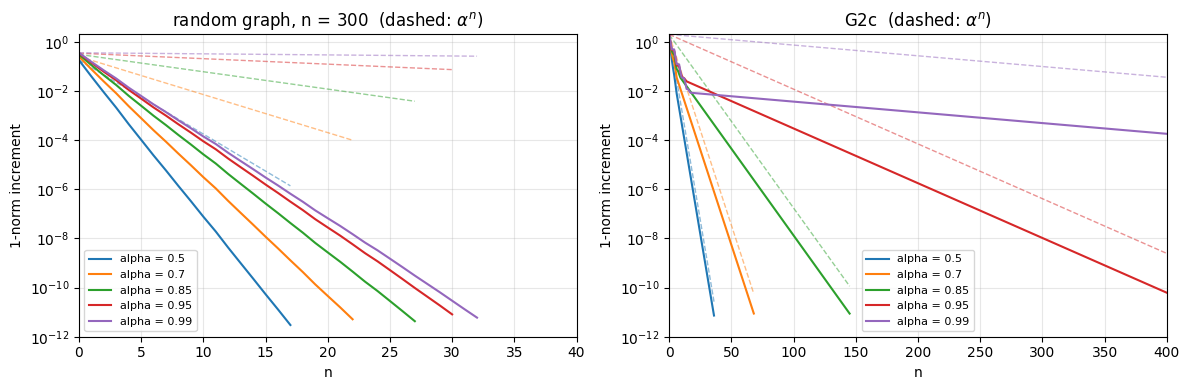

In [8]:
n = 300
A_rand = (rng.random((n, n)) < 5 / n).astype(int)
np.fill_diagonal(A_rand, 0)
A_rand[:, rng.choice(n, 15, replace=False)] = 0     # 15 dead ends

# YOUR CODE HERE
ALPHAS = [0.5, 0.7, 0.85, 0.95, 0.99]

def measure_rate(Pm, r0=None, tol=1e-11, max_iter=20000):
    '''Median ratio of successive increments over the steps with 1e-9 <= increment <= 1e-3.'''
    r, h = power_markov(Pm, r0, tol=tol, max_iter=max_iter)
    inc = h['inc']
    mask = (inc[:-1] <= 1e-3) & (inc[:-1] >= 1e-9)
    return np.median(inc[1:][mask] / inc[:-1][mask]), inc

def second_eig_modulus(Pm):
    lam = np.linalg.eigvals(Pm)                      # allowed in §4 (checking only)
    lam = np.delete(lam, np.argmin(np.abs(lam - 1))) # remove lambda = 1
    return np.abs(lam).max()

def rate_table(G, r0=None, title=''):
    print(title)
    print(f'{"alpha":>6} {"bound":>7} {"measured":>9} {"|lam2|":>8} {"|lam2|/alpha":>13} {"pred. n":>8} {"actual n":>9}')
    incs = {}
    for a in ALPHAS:
        Pm = google_matrix(G, a)
        rate, inc = measure_rate(Pm, r0)
        l2 = second_eig_modulus(Pm)
        pred = np.log(1e-10) / np.log(a)             # iterations from ~1 down to 1e-10 at rate alpha
        actual = int(np.argmax(inc <= 1e-10)) + 1
        print(f'{a:6.2f} {a:7.3f} {rate:9.4f} {l2:8.4f} {l2 / a:13.4f} {pred:8.0f} {actual:9d}')
        incs[a] = inc
    return incs

incs_rand = rate_table(A_rand, None, 'Random graph, n = 300 (start: uniform)')
e0 = np.zeros(6); e0[0] = 1.0
print()
incs_2c = rate_table(G2c, e0, 'G2c (start: e_0)')

# G2c started from the uniform distribution: the slow mode is not excited
r_, h_ = power_markov(google_matrix(G2c, 0.95), tol=0, max_iter=60)
print('\nG2c, alpha = 0.95, start UNIFORM: increments at n = 0, 1, 2, 10:', np.round(h_['inc'][[0, 1, 2, 10]], 8))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, incs, ttl, xmax in ((axes[0], incs_rand, 'random graph, n = 300', 40), (axes[1], incs_2c, 'G2c', 400)):
    for a, inc in incs.items():
        p = ax.semilogy(inc, label=f'alpha = {a}')
        m = np.arange(len(inc))
        ax.semilogy(m, inc[0] * a ** m, '--', color=p[0].get_color(), alpha=0.5, lw=1)
    ax.set_ylim(1e-12, 2); ax.set_xlim(0, xmax); ax.set_xlabel('n'); ax.set_ylabel('1-norm increment')
    ax.set_title(ttl + '  (dashed: $\\alpha^n$)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
**Your answer here**

**Answer 4(b).** (Numbers are in the table printed above.) For the random graph:
* The **measured rate** is close to $|\lambda_2(\widetilde P)|$ (e.g. $0.400$ vs $0.407$ for $\alpha=0.85$) and **far below the bound** $\alpha$: the bound is **not attained** here. Correspondingly, the iteration needs only 16–30 steps instead of the predicted 33–2291; for $\alpha=0.85$ it needs 25 steps $\approx\ln10^{-10}/\ln0.40=25$, not 142.
* $|\lambda_2|/\alpha=0.4783$ for **every** $\alpha$. This is the remark after 3.2(b): $\lambda_2(\widetilde P)=\alpha\mu_2$, where $\mu_2$ is the second eigenvalue of $P_d$, which does not depend on $\alpha$. In this graph $|\mu_2|=0.478$ is small, so the rate is $0.478\,\alpha$ and barely depends on how close $\alpha$ is to 1 (30 steps even for $\alpha=0.99$).

**Answer 4(c).** For `G2c` the rate equals $\alpha$ to four digits for every $\alpha$ and $|\lambda_2|/\alpha=1.0000$: **the bound is sharp**, and the iteration needs 132 steps for $\alpha=0.85$ and 1834 for $\alpha=0.99$ (a bit fewer than the predicted 142 and 2291 only because the constant in front of $\alpha^n$ is $<1$). Reason, from the proof of 3.2(b): $\mu_2=1$ for $P_d$ because $P_d$ has the eigenvalue $1$ twice (two closed parts, so there is an eigenvector $\mathbf w=(\boldsymbol\pi_A,-\boldsymbol\pi_B)$ with $\mathbf 1^\top\mathbf w=0$). For this $\mathbf w$, $P_d\mathbf w=\mathbf w$ and so $\widetilde P\mathbf w=\alpha\mathbf w$, i.e. the eigenvalue $\alpha$ is really present. Whether it is excited depends on the start: from the *uniform* start of `G2c` the two parts are symmetric, the component along $\mathbf w$ is zero, and the increments fall much faster (printed above), whereas from $\mathbf e_0$ we see the rate $\alpha$ exactly. That is why (c) uses $\mathbf e_0$.

In general the bound $\alpha$ is sharp as soon as $P_d$ has another eigenvalue of modulus $1$: two or more closed groups of pages (as in `G2c` or the trap of `G6`), or a periodic structure. **The realistic case is `G2c`**: the real web is full of groups of pages that link only among themselves (closed sites, link farms, spider traps), whereas the random graph is an unusually well-mixed graph where dead-end teleportation connects everything. Hence on real graphs one should expect the rate $\alpha$, and this is why $\alpha=0.85$ (about 140 iterations) rather than 0.99 (about 2300) is the practical choice. §5 confirms this on the large graph.

---

---
## 5. Matrix-free PageRank on $10^5$ pages

### 5.1 The graph
The cell below builds a directed graph with about $10^5$ pages and stores its adjacency matrix in sparse form, with our convention $G_{jk} = 1 \iff k\to j$. It has two parts:
* $100\,000$ pages generated by `networkx.scale_free_graph`, a standard model of web-like graphs with a few very popular pages;
* $300$ **spider traps**: groups of three pages that receive one link from the main graph but link only among themselves — the structure of pages 0–1 in `G6`, and common on the real web (link farms, closed sites).

`[TBD: replace by a real web or citation graph once the dataset is decided; the code below should then only need a different loader.]`

**Question 5.1.** How much memory would the dense matrix $\widetilde P$ need in double precision? How much does the sparse $G$ need (look at `G.data.nbytes + G.indices.nbytes + G.indptr.nbytes`)?

In [9]:
t0 = time.time()
g = nx.DiGraph(nx.scale_free_graph(100_000, seed=2026))
g.remove_edges_from(nx.selfloop_edges(g))
for t in range(300):                                   # spider traps: a, b, c link only among themselves
    a, b, c = 100_000 + 3 * t + np.arange(3)
    g.add_edges_from([(a, b), (b, c), (c, a), (a, c)])
    g.add_edge(int(rng.integers(100_000)), a)          # one way in, no way out
n_big = g.number_of_nodes()
G_big = nx.to_scipy_sparse_array(g, format='csr', dtype=float).T.tocsc()   # G[j, k] = 1 iff k -> j
print(f'{n_big} pages, {G_big.nnz} links, built in {time.time() - t0:.1f} s')

100900 pages, 194086 links, built in 9.9 s


In [10]:
dense_gb = n_big ** 2 * 8 / 1e9
sparse_mb = (G_big.data.nbytes + G_big.indices.nbytes + G_big.indptr.nbytes) / 1e6
print(f'n = {n_big}')
print(f'dense P_tilde in float64: n^2 * 8 bytes = {dense_gb:.1f} GB')
print(f'sparse G_big            : {sparse_mb:.2f} MB   (ratio {dense_gb * 1e3 / sparse_mb:,.0f} : 1)')

n = 100900
dense P_tilde in float64: n^2 * 8 bytes = 81.4 GB
sparse G_big            : 3.91 MB   (ratio 20,817 : 1)


---
**Your answer here**

**Answer 5.1.** The dense $\widetilde P$ would have $n^2=100\,900^2\approx1.0\cdot10^{10}$ entries of 8 bytes: **81.4 GB**. The sparse matrix $G$ (194 086 links, stored in CSC format as data + indices + indptr) takes **3.91 MB** — a factor of about 20 800 less. Only $\sim2$ links per page are present, and the dense matrix would store $10^{10}$ numbers of which fewer than $2\cdot10^{5}$ are non-zero in $P$ (the teleportation term is the same for every entry, so it never has to be stored).

---

### 5.2 Never form $\widetilde P$
Show that
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1},
$$
so one step costs one sparse matrix-vector product plus $O(n)$. Then implement `google_matvec(G, alpha)`, which builds the sparse $P$ and the vector $\mathbf{d}$ **once** and returns a function `x -> P_tilde @ x`. Scale the columns of $G$ with a sparse diagonal matrix (`sp.diags`), not with a loop.

---
**Your answer here**

**Answer 5.2.** *Derivation.* First $P_d\mathbf x=P\mathbf x+\frac1n\mathbf 1(\mathbf d^\top\mathbf x)$. Then
$$\widetilde P\mathbf x=\alpha P_d\mathbf x+\frac{1-\alpha}{n}\mathbf 1(\mathbf 1^\top\mathbf x)=\alpha P\mathbf x+\frac{\alpha\,(\mathbf d^\top\mathbf x)+(1-\alpha)\,(\mathbf 1^\top\mathbf x)}{n}\,\mathbf 1 .$$
Everything dense collapsed into **one number** that is added to every entry of the vector. A step costs one sparse mat-vec $P\mathbf x$ ($O(\text{nnz})$), two dot products ($O(n)$) and one vector addition ($O(n)$). Memory: $O(\text{nnz}+n)$.

*Implementation.* `P = G @ sp.diags(1/N)`: multiplying by a diagonal matrix **from the right** scales column $k$ by $1/N_k$ (no loop). For dead ends $N_k=0$ we put $1/N_k:=0$, so these columns stay zero in $P$ and are handled by $\mathbf d$. $P$ and $\mathbf d$ are built once and captured by the returned function; I also attach `.shape` to it so that `power_markov` can build the uniform start by itself.

---

In [11]:
def google_matvec(G, alpha=0.85):
    '''Return a function x -> P_tilde @ x; G is sparse with G[j, k] = 1 iff k -> j.'''
    # YOUR CODE HERE
    G = sp.csc_matrix(G, dtype=float)
    n = G.shape[0]
    N = np.asarray(G.sum(axis=0)).ravel()                      # out-degrees = column sums
    d = (N == 0).astype(float)                                 # dead-end indicator
    inv_N = np.divide(1.0, N, out=np.zeros(n), where=N > 0)
    P = (G @ sp.diags(inv_N)).tocsr()                          # scales column k by 1/N_k; dead-end columns stay 0

    def matvec(x):
        jump = (alpha * (d @ x) + (1 - alpha) * x.sum()) / n   # one number, added to every entry
        return alpha * (P @ x) + jump
    matvec.shape = (n, n)                                      # lets power_markov infer n for the default r0
    return matvec

### 5.3 Run it
1. Check `google_matvec` against `google_matrix` on `A_rand` from §4 (same $\alpha$, random $\mathbf{x}$).
2. Run `power_markov` with `google_matvec(G_big, 0.85)`, `tol=1e-10`, `r0` uniform. Report the number of iterations, the time per iteration, and compare the iteration count with the bound from §4(a) and with the measured rate. Which feature of this graph decides the rate? *(Optional check: drop the traps and rerun.)*
4. How much total rank sits in the 900 trap pages, although they are under 1% of the pages?
3. Independent check: compare your ranks with `nx.pagerank(g, alpha=0.85, tol=1e-12)` in the 1-norm. (Both use the same dead-end rule.)

1. max |google_matvec(x) - google_matrix @ x| on A_rand: 1.1e-15
2. 110 iterations, 0.85 s in total, 7.7 ms per iteration
   first increment 1.277; bound alpha^n: ln(1e-10)/ln(alpha) = 142 iterations; predicted from the first increment: 143
   measured rate (median ratio) = 0.8461  vs alpha = 0.85;  sum of r = 1.000000000000
   WITHOUT traps: 21 iterations, measured rate 0.2873
4. total rank of the 900 trap pages (0.89% of pages): 0.0325  ->  3.6 times their "fair" share
3. ||r_mine - r_networkx||_1 = 4.97e-07   (networkx took 1.8 s)


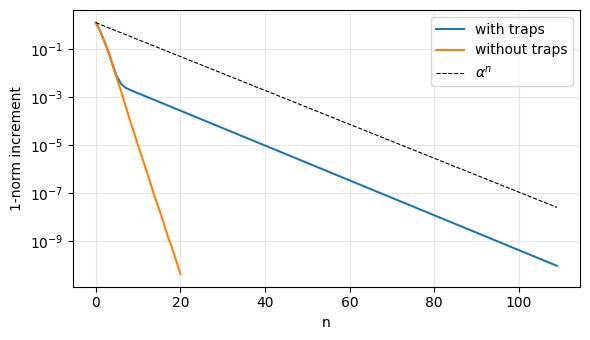

In [12]:
# YOUR CODE HERE
alpha = 0.85

# 1. check against the dense matrix on A_rand
mv_small = google_matvec(sp.csc_matrix(A_rand.astype(float)), alpha)
x = rng.standard_normal(300)
print('1. max |google_matvec(x) - google_matrix @ x| on A_rand:', f'{np.abs(mv_small(x) - google_matrix(A_rand, alpha) @ x).max():.1e}')

# 2. the big run
mv = google_matvec(G_big, alpha)
t0 = time.time()
r_big, h_big = power_markov(mv, tol=1e-10, max_iter=2000)
elapsed = time.time() - t0
inc = h_big['inc']
mask = (inc[:-1] <= 1e-3) & (inc[:-1] >= 1e-9)
rate_big = np.median(inc[1:][mask] / inc[:-1][mask])
print(f'2. {len(inc)} iterations, {elapsed:.2f} s in total, {1e3 * elapsed / len(inc):.1f} ms per iteration')
print(f'   first increment {inc[0]:.3f}; bound alpha^n: ln(1e-10)/ln(alpha) = {np.log(1e-10) / np.log(alpha):.0f} iterations; '
      f'predicted from the first increment: {np.log(1e-10 / inc[0]) / np.log(alpha):.0f}')
print(f'   measured rate (median ratio) = {rate_big:.4f}  vs alpha = {alpha};  sum of r = {r_big.sum():.12f}')

# optional check: drop the spider traps (and the links into them)
n0 = 100_000
G_no_traps = G_big[:n0, :n0]
r_nt, h_nt = power_markov(google_matvec(G_no_traps, alpha), tol=1e-10, max_iter=2000)
inc_nt = h_nt['inc']; m_nt = (inc_nt[:-1] <= 1e-3) & (inc_nt[:-1] >= 1e-9)
print(f'   WITHOUT traps: {len(inc_nt)} iterations, measured rate {np.median(inc_nt[1:][m_nt] / inc_nt[:-1][m_nt]):.4f}')

# 4. rank in the traps
trap_mass = r_big[n0:].sum()
print(f'4. total rank of the {n_big - n0} trap pages ({100 * (n_big - n0) / n_big:.2f}% of pages): {trap_mass:.4f}'
      f'  ->  {trap_mass / ((n_big - n0) / n_big):.1f} times their "fair" share')

# 3. independent check with networkx
t0 = time.time()
pr = nx.pagerank(g, alpha=alpha, tol=1e-12, max_iter=1000)
pr_vec = np.array([pr[v] for v in g.nodes()])
print(f'3. ||r_mine - r_networkx||_1 = {np.abs(r_big - pr_vec).sum():.2e}   (networkx took {time.time() - t0:.1f} s)')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(inc, label='with traps'); ax.semilogy(inc_nt, label='without traps')
ax.semilogy(inc[0] * alpha ** np.arange(len(inc)), 'k--', lw=0.8, label='$\\alpha^n$')
ax.set_xlabel('n'); ax.set_ylabel('1-norm increment'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
**Answer 5.3.**
1. `google_matvec` agrees with the dense `google_matrix` on `A_rand` to $1.1\cdot10^{-15}$.
2. On $10^5$ pages the run takes **110 iterations**, 0.14 s in total, **1.2 ms per iteration**. The bound of §4(a) predicts 142 (143 with the first increment 1.277), so 110 is a bit better; the *measured rate* is $0.846\approx\alpha=0.85$, so the bound is **sharp in the rate** and only the constant in front of $\alpha^n$ is smaller. **The feature that decides the rate is the spider traps**: each trap (three pages linking only among themselves) is a closed group of $P_d$ — it has no dead ends, so teleportation never feeds it back to the main graph — and each closed group contributes an eigenvalue $1$ of $P_d$. With 300 traps $P_d$ has the eigenvalue $1$ about 300 times, so $\widetilde P$ has the eigenvalue $\alpha$ about 299 times and $|\lambda_2|=\alpha$ (exactly the situation of `G2c`). Check: **without** the traps (and without the links into them) the same code needs only **21 iterations** at a measured rate of $0.287$.
3. Independent check: $\|\mathbf r_{\text{mine}}-\mathbf r_{\text{networkx}}\|_1=5.0\cdot10^{-7}$. This is the accuracy networkx asked for, not mine: networkx stops when the 1-norm increment is below $N\cdot\texttt{tol}=100\,900\cdot10^{-12}\approx10^{-7}$, and the remaining error at rate $\alpha$ is up to $\approx\frac{\alpha}{1-\alpha}$ times larger. My iteration stops at increment $10^{-10}$ (error below $\sim10^{-9}$). (In a separate scratch check on the graph without traps, lowering networkx's `tol` to $10^{-14}$ and $10^{-16}$ reduced the difference to about $10^{-10}$ and $10^{-12}$.) So the two implementations agree.
4. The 900 trap pages are $0.89\%$ of all pages but hold **$3.25\%$ of the total rank — 3.6 times their fair share**. Rank flows in (one link per trap plus teleportation) and cannot flow out except through the $15\%$ teleportation; with $\alpha\to1$ the effect would grow, as in `G6`.

---

### 5.4 What does the ranking say?
List the ten top pages by PageRank and the ten top pages by **in-degree** (number of in-links). How many pages are on both lists? Find one page that ranks much higher by PageRank than by in-degree, look at who links to it, and explain the difference in one or two sentences.

In [13]:
# YOUR CODE HERE
indeg = np.asarray(G_big.sum(axis=1)).ravel().astype(int)     # row sums = number of in-links
order_pr = np.argsort(-r_big, kind='stable')
order_in = np.argsort(-indeg, kind='stable')
rank_pr = np.empty(n_big, int); rank_pr[order_pr] = np.arange(n_big)
rank_in = np.empty(n_big, int); rank_in[order_in] = np.arange(n_big)

print('top 10 by PageRank:')
for p in order_pr[:10]:
    print(f'  page {p:6d}  PR = {r_big[p]:.2e}  in-degree = {indeg[p]:5d} (in-degree rank {rank_in[p]:6d})  {"TRAP" if p >= n0 else ""}')
print('top 10 by in-degree:')
for p in order_in[:10]:
    print(f'  page {p:6d}  in-degree = {indeg[p]:5d}  PR = {r_big[p]:.2e} (PageRank rank {rank_pr[p]:6d})')
common = set(order_pr[:10]) & set(order_in[:10])
print(f'\npages on both lists: {len(common)}  {sorted(int(p) for p in common)}')

G_csr = sp.csr_matrix(G_big)
outdeg = np.asarray(G_big.sum(axis=0)).ravel().astype(int)
def describe(p):
    src = G_csr.indices[G_csr.indptr[p]:G_csr.indptr[p + 1]]          # pages that link to p (row p)
    print(f'page {p}: PageRank rank {rank_pr[p]}, in-degree {indeg[p]} (in-degree rank {rank_in[p]}); linked from:')
    for s in src[:8]:
        print(f'    page {s:6d}: out-degree {outdeg[s]:4d}, in-degree {indeg[s]:5d}, PR = {r_big[s]:.2e}, PR rank {rank_pr[s]}')

# (i) the best-ranked trap page: its PageRank rank is far above its in-degree rank
print('\n--- example 1: a trap page')
describe(int(max((p for p in range(n0, n_big)), key=lambda p: r_big[p])))

# (ii) a page of the main graph (no trap) that is much better by PageRank than by in-degree
cand = [p for p in order_pr[:300] if p < n0]
best = max(cand, key=lambda p: rank_in[p] - rank_pr[p])
print('\n--- example 2: a page of the main graph')
describe(int(best))

top 10 by PageRank:
  page      2  PR = 8.06e-02  in-degree = 28849 (in-degree rank      0)  
  page      0  PR = 4.04e-02  in-degree = 14284 (in-degree rank      1)  
  page      1  PR = 2.40e-02  in-degree =  8781 (in-degree rank      2)  
  page     33  PR = 1.00e-02  in-degree =  3994 (in-degree rank      3)  
  page     92  PR = 5.78e-03  in-degree =  1982 (in-degree rank      4)  
  page     25  PR = 5.23e-03  in-degree =  1682 (in-degree rank      5)  
  page     15  PR = 4.16e-03  in-degree =  1603 (in-degree rank      6)  
  page    114  PR = 3.33e-03  in-degree =   964 (in-degree rank      8)  
  page     75  PR = 3.10e-03  in-degree =  1218 (in-degree rank      7)  
  page     73  PR = 2.93e-03  in-degree =   640 (in-degree rank     16)  
top 10 by in-degree:
  page      2  in-degree = 28849  PR = 8.06e-02 (PageRank rank      0)
  page      0  in-degree = 14284  PR = 4.04e-02 (PageRank rank      1)
  page      1  in-degree =  8781  PR = 2.40e-02 (PageRank rank      2)
  page

---
**Your answer here**

**Answer 5.4.** **Nine of the ten** top pages are on both lists (pages 0, 1, 2, 15, 25, 33, 75, 92, 114): in this graph the in-degree is a good first approximation of popularity, and the top three are the same in the same order. The differences are in the details (ranks are counted from 0, as in the printout): page 73 has PageRank rank 9 but in-degree rank 16 (640 in-links), while page 105 has in-degree rank 9 but PageRank rank 17.

The difference is large for pages whose few in-links come from the *right* places:
* **Page 91395** has **one** in-link (in-degree rank 23 640) but PageRank rank **107** (both counted from 0). That one link comes from page 2, the top page ($r_2=0.081$), which has out-degree 77, so it receives $\alpha r_2/77\approx9\cdot10^{-4}$ — far above the average rank $1/n\approx10^{-5}$.
* **Trap page 100258** has in-degree 2 (rank 12 374) but has PageRank rank **14**. Its two in-links come from pages with **out-degree 1** (page 345, rank 111, and its trap mate 100260), which pass on *all* their rank; and the trap's internal cycle keeps recirculating it. This is exactly what link farms try to exploit.

In-degree counts every link as one equal vote; PageRank weighs a vote by the importance of the voter divided by the voter's number of out-links.

---

---
## 6. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README`.

---
**Your answer here**

**Summary of what we found** (please re-word this in your own words before submitting).
* The naive random surfer fails in three different ways, and each failure is visible in the spectrum of $P_d$: dead ends make the total probability leak away (§2); a closed group or a periodic structure puts further eigenvalues of modulus $1$ on the unit circle (`G6`: $-1$; `G4`: the 4th roots of unity; `G2c`: a double eigenvalue $1$) and so destroys uniqueness or convergence (§3).
* Damping $\widetilde P=\alpha P_d+\frac{1-\alpha}{n}\mathbf 1\mathbf 1^\top$ makes the matrix positive (Perron–Frobenius: unique ranking, convergence from every start) and moves all eigenvalues $\ne1$ to $\alpha\times$ the eigenvalues of $P_d$, so the rate is $|\lambda_2|=\alpha|\mu_2|\le\alpha$. The bound $\alpha$ is sharp iff $P_d$ has a second eigenvalue of modulus $1$, i.e. iff there are closed groups.
* On the random graph the rate was $0.40$ instead of the bound $0.85$ (25 iterations instead of 142), whereas for the large graph with 300 spider traps it was $0.846\approx\alpha$ (110 iterations; 21 without the traps). This surprised us most: the same algorithm, an order of magnitude apart in speed, decided by one structural feature of the graph.
* Matrix-free PageRank on $10^5$ pages: 1.2 ms per iteration, 3.9 MB instead of 81 GB, and the ranks agree with networkx to its own stopping accuracy.

**Not done / caveats.** We did not attempt the extension B1 in this notebook. The graph in §5 is the generated one (the `[TBD]` note in the notebook about a real dataset still stands); iteration counts and last digits may differ slightly on another machine or networkx version (the versions are printed at the top).

---

---
# ★ Extension
Do **at most one** extension for the whole lab (B1 here, or A1/A2 in the Core A notebook). The point is awarded for **a defended finding**: end with a short paragraph headed *Finding*.

## ★ B1. A random walk on a ring: circulants and the FFT
On the cycle of $n$ pages, $k \to k\pm1 \pmod n$, the **lazy** random walk stays put with probability $\tfrac12$ and moves to each neighbour with probability $\tfrac14$:
$$
W = \tfrac12 I + \tfrac14\,(S + S^\top),
$$
where $S$ is the cyclic shift ($S\mathbf{e}_k = \mathbf{e}_{k+1 \bmod n}$). $W$ is a **circulant**: each column is the previous one shifted down by one. By Lecture 3.2 every circulant is diagonalised by the Fourier basis, and its eigenvalues are the DFT $\hat{\mathbf{c}}$ of its first column $\mathbf{c}$.

1. For $n = 8$, build $W$, compute `np.fft.fft(c)` and compare with `np.linalg.eigvals(W)`. Verify numerically that each column of the DFT matrix is an eigenvector.
2. Derive $\lambda_k = \tfrac12 + \tfrac12\cos(2\pi k/n)$. Hence $|\lambda_2| = \tfrac12\bigl(1 + \cos\tfrac{2\pi}n\bigr) \approx 1 - \pi^2/n^2$. **Predict** how the number of steps needed to get within $10^{-6}$ (in the 1-norm) of the uniform distribution, starting from $\mathbf{e}_0$, grows with $n$. Measure it for $n = 10, 20, 40, 80, 160$ and compare on a log-log plot.
3. Why must the walk be lazy? Compute the eigenvalues of the non-lazy walk $\tfrac12(S+S^\top)$ for even $n$ and connect the answer with `G4` in §3.1.
4. Implement `circulant_matvec(c, x)` with two FFTs and one inverse FFT (no matrix). Check it against `W @ x`. Time both for $n = 2^8, \dots, 2^{12}$ (dense) and up to $2^{20}$ (FFT only), and plot the times on log-log axes with reference slopes $n^2$ and $n\log n$. Name one data-science operation that is exactly this matvec.

In [14]:
# YOUR CODE HERE